# Classification of Supernovae (SN Ia vs Non-SN Ia)

###  Imports & Configuration

In [4]:
import os
import numpy as np
import pandas as pd
from matplotlib import pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.metrics import (
    confusion_matrix, ConfusionMatrixDisplay,
    precision_score, recall_score, f1_score, accuracy_score)
from catboost import CatBoostClassifier
import random
from sklearn.model_selection import StratifiedKFold
from config import config
cfg = config.classification
random.seed(cfg.seed)
np.random.seed(cfg.seed)
print(cfg.seed)

os.makedirs(cfg.figures_dir, exist_ok=True)

42


### Dataset

In [6]:
df = pd.read_csv(config.globals.abs_mag_csv) # Load dataset

# Show unique transient types
print("Printing Transient Types:", df['Type'].unique())

# Group all non-SN Ia as 'Non-SNIa'
df.loc[df['Type'] != 'SNIa', 'Type'] = 'Non-SNIa'

 
base_feats = ['Abs_Mag', 'Beta1', 'Beta2']



extra_feats = ['Photo_z']    # non-band features
bands=[ 'R', 'Z', 'Y', 'J', 'H', 'F']

#feature_cols = [f"{b}_{feat}" for b in bands for feat in base_feats] + extra_feats
feature_cols = [f"{b}_{feat}" for b in config.globals.bands for feat in base_feats] + extra_feats
#feature_cols = [f"{b}_{feat}" for b in config.globals.bands for feat in base_feats]

label_col = 'Type'



feature = df[feature_cols]
label = df[label_col]
print(f"Number of features per LC: {feature.iloc[0].shape}") 

print("Label counts:\n", label.value_counts())


Printing Transient Types: ['SNIa' 'CCSN' 'SNIax' 'SNIa-91bg' 'SLSN' 'ILOT' 'TDE' 'PISN']
Number of features per LC: (19,)
Label counts:
 Type
Non-SNIa    35397
SNIa        21483
Name: count, dtype: int64


###  Train CatBoost 

In [7]:
#Random Split
# --- Metrics ---

SEED = cfg.seed



def metrics(y_true, y_pred):
    return dict(acc=accuracy_score(y_true, y_pred),
                prec=precision_score(y_true, y_pred, pos_label='SNIa'),
                rec=recall_score(y_true, y_pred, pos_label='SNIa'),
                f1=f1_score(y_true, y_pred, pos_label='SNIa'))

# --- Repeated random splits, all derived from one seed ---
rng = np.random.default_rng(SEED)
run_seeds = rng.integers(0, 1000, size=cfg.n_folds).tolist()

train_scores, val_scores, test_scores = [], [], []

for i, seed in enumerate(run_seeds):
    print(f"RUN {i+1}/{cfg.n_folds}")
    x_train1, x_test, y_train1, y_test = train_test_split(
        feature, label, test_size=cfg.test_size, random_state=seed, stratify=label)
    x_train, x_val, y_train, y_val = train_test_split(
        x_train1, y_train1, test_size=0.1, random_state=seed, stratify=y_train1)

    if i == 0:   # sizes are the same for every run
        print(f"Total data size:      {len(feature)}")
        print(f"Training data size:   {len(x_train)}")
        print(f"Validation data size: {len(x_val)}")
        print(f"Test data size:       {len(x_test)}")
        print(f"No. of features:      {x_train.shape[1]}")

    clf = CatBoostClassifier(verbose=False, random_seed=seed, depth=8)
    clf.fit(x_train, y_train)

    train_scores.append(metrics(y_train, clf.predict(x_train).ravel()))
    val_scores.append(metrics(y_val, clf.predict(x_val).ravel()))
    test_scores.append(metrics(y_test, clf.predict(x_test).ravel()))

# --- Results ---
for name, s in [("Train", train_scores), ("Val", val_scores), ("Test", test_scores)]:
    df = pd.DataFrame(s).agg(['mean', 'std']).T * 100
    print(f"\n{name} (mean ± std over {cfg.n_folds} splits):")
    for metric, row in df.iterrows():
        print(f"  {metric:5s}: {row['mean']:.1f} ± {row['std']:.1f}")

RUN 1/5
Total data size:      56880
Training data size:   40953
Validation data size: 4551
Test data size:       11376
No. of features:      19
RUN 2/5
RUN 3/5
RUN 4/5
RUN 5/5

Train (mean ± std over 5 splits):
  acc  : 99.0 ± 0.1
  prec : 98.9 ± 0.1
  rec  : 98.5 ± 0.1
  f1   : 98.7 ± 0.1

Val (mean ± std over 5 splits):
  acc  : 96.4 ± 0.2
  prec : 96.2 ± 0.3
  rec  : 94.2 ± 0.5
  f1   : 95.2 ± 0.3

Test (mean ± std over 5 splits):
  acc  : 96.3 ± 0.1
  prec : 95.8 ± 0.2
  rec  : 94.2 ± 0.3
  f1   : 95.0 ± 0.1


In [12]:
# --- 5-fold stratified cross-validation ---
N_SPLITS = 5
skf = StratifiedKFold(n_splits=N_SPLITS, shuffle=True, random_state=SEED)

train_scores, val_scores, test_scores = [], [], []   # metrics for each fold

for i, (train_idx, test_idx) in enumerate(skf.split(feature, label)):
    # 1. Split this fold: 80% train+val, 20% test
    x_train1, y_train1 = feature.iloc[train_idx], label.iloc[train_idx]
    x_test,   y_test   = feature.iloc[test_idx],  label.iloc[test_idx]

    # 2. Split 10% of train off as validation
    x_train, x_val, y_train, y_val = train_test_split(
        x_train1, y_train1, test_size=0.1, random_state=SEED , stratify=y_train1)

    # 3. Train
    clf = CatBoostClassifier(verbose=False, random_seed=SEED , depth=8)
    clf.fit(x_train, y_train)

    # 4. Predict and score
    y_pred = clf.predict(x_test).ravel()
    train_scores.append(metrics(y_train, clf.predict(x_train).ravel()))
    val_scores.append(metrics(y_val, clf.predict(x_val).ravel()))
    test_scores.append(metrics(y_test, y_pred))

   

    print(f"fold {i+1}: test acc = {test_scores[-1]['acc']*100:.1f}%")

# --- Average over the 5 folds ---
for name, s in [("Train", train_scores), ("Val", val_scores), ("Test", test_scores)]:
    scores = pd.DataFrame(s) * 100
    print(f"\n{name} (mean ± std over {N_SPLITS} folds):")
    for metric in scores.columns:
        print(f"  {metric:5s}: {scores[metric].mean():.1f} ± {scores[metric].std():.1f}")



fold 1: test acc = 95.8%
fold 2: test acc = 96.3%
fold 3: test acc = 95.8%
fold 4: test acc = 96.5%
fold 5: test acc = 96.3%

Train (mean ± std over 5 folds):
  acc  : 99.0 ± 0.1
  prec : 98.9 ± 0.1
  rec  : 98.5 ± 0.1
  f1   : 98.7 ± 0.1

Val (mean ± std over 5 folds):
  acc  : 96.3 ± 0.3
  prec : 95.8 ± 0.4
  rec  : 94.2 ± 0.5
  f1   : 95.0 ± 0.4

Test (mean ± std over 5 folds):
  acc  : 96.2 ± 0.3
  prec : 95.7 ± 0.4
  rec  : 94.1 ± 0.5
  f1   : 94.9 ± 0.4


Photo_z      18.98
Z_Abs_Mag     9.67
H_Abs_Mag     9.48
R_Abs_Mag     6.79
H_Beta1       6.24
Y_Abs_Mag     6.21
J_Beta1       4.98
H_Beta2       4.70
Z_Beta1       4.61
R_Beta2       4.05
J_Abs_Mag     3.81
R_Beta1       3.29
Z_Beta2       3.28
Y_Beta1       3.12
F_Beta2       2.53
J_Beta2       2.45
F_Abs_Mag     2.21
Y_Beta2       2.06
F_Beta1       1.53


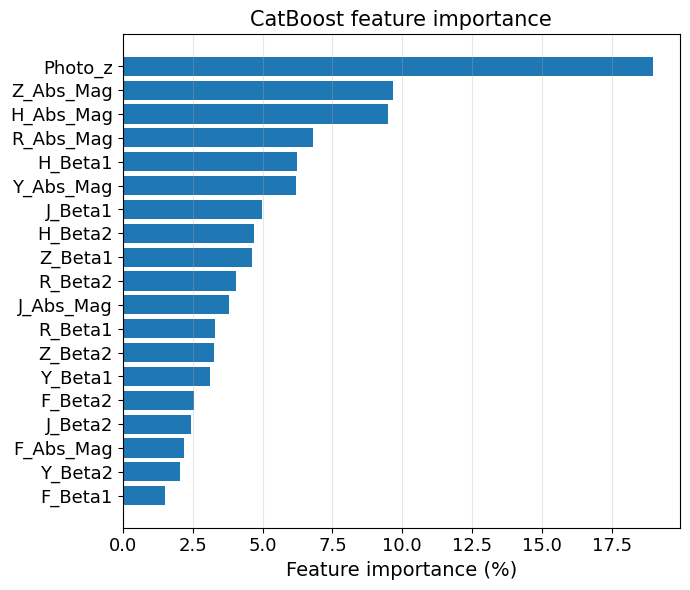

In [11]:
# --- Feature importance from the model ---

imp = pd.Series(clf.get_feature_importance(), index=clf.feature_names_).sort_values()
print(imp.sort_values(ascending=False).round(2).to_string())

# --- Plot ---
fig, ax = plt.subplots(figsize=(7, 6))
ax.barh(imp.index, imp.values, color='tab:blue')

ax.set_xlabel('Feature importance (%)', fontsize=14)
ax.set_title('CatBoost feature importance', fontsize=15)
ax.tick_params(axis='both', labelsize=13)
ax.set_xlim(0, imp.max() * 1.05)
ax.grid(axis='x', alpha=0.3)

plt.tight_layout()
os.makedirs("Figures", exist_ok=True)
plt.savefig(f'{cfg.figures_dir}/Feature_importance_barh.png', dpi=200)
plt.show()

###  Confusion Matrix (last run)

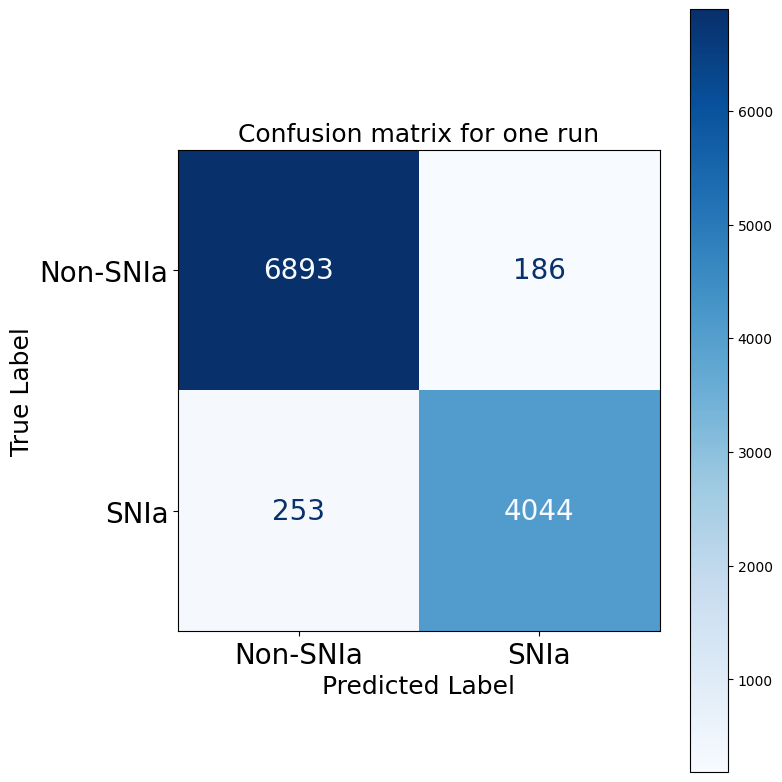

In [12]:
#Confusion Matrix
y_pred_test = clf.predict(x_test).ravel()
cm = confusion_matrix(y_test, y_pred_test)
disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=clf.classes_)

fig, ax = plt.subplots(figsize=(8, 8))
disp.plot(ax=ax, cmap='Blues', values_format='d')

# Customize font sizes
plt.setp(ax.get_xticklabels(), fontsize=20)
plt.setp(ax.get_yticklabels(), fontsize=20)
for label in ax.texts:
    label.set_fontsize(20)

plt.xlabel('Predicted Label', fontsize=18)
plt.ylabel('True Label', fontsize=18)
plt.title('Confusion matrix for one run', fontsize=18)
os.makedirs("Figures", exist_ok=True)
plt.tight_layout()
plt.savefig(f'{cfg.figures_dir}/Confusion_Matrix.png')
plt.show()


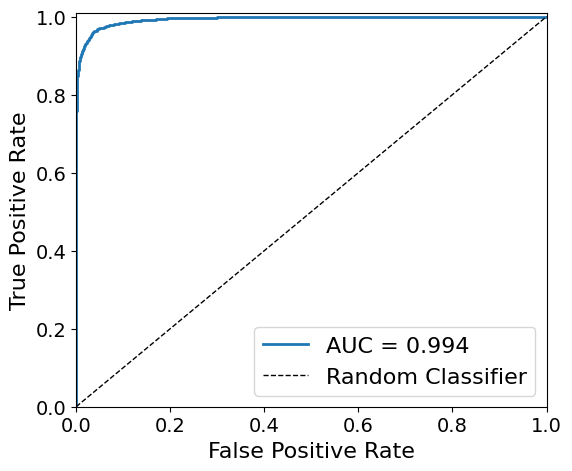

In [18]:
import matplotlib.pyplot as plt
from sklearn.metrics import roc_curve, auc

plt.rcParams.update({
    'axes.labelsize':   16,   # x/y labels
    'xtick.labelsize':  14,   # tick numbers
    'ytick.labelsize':  14,
    'legend.fontsize':  16,
   })

ia_col = list(clf.classes_).index('SNIa')
p      = clf.predict_proba(x_test)[:, ia_col]
y_bin  = np.asarray(y_test) == 'SNIa'

fpr, tpr, _ = roc_curve(y_bin, p)
roc_auc = auc(fpr, tpr)

fig, ax = plt.subplots(figsize=(6, 5))
ax.plot(fpr, tpr, lw=2, label=f'AUC = {roc_auc:.3f}')
ax.plot([0, 1], [0, 1], 'k--', lw=1, label='Random Classifier')
ax.set_xlabel('False Positive Rate')
ax.set_ylabel('True Positive Rate')
ax.set_xlim(0, 1); ax.set_ylim(0, 1.01)
ax.legend(loc='lower right')
plt.tight_layout()
plt.savefig(f'{cfg.figures_dir}/ROC_AUC.png')
plt.show()

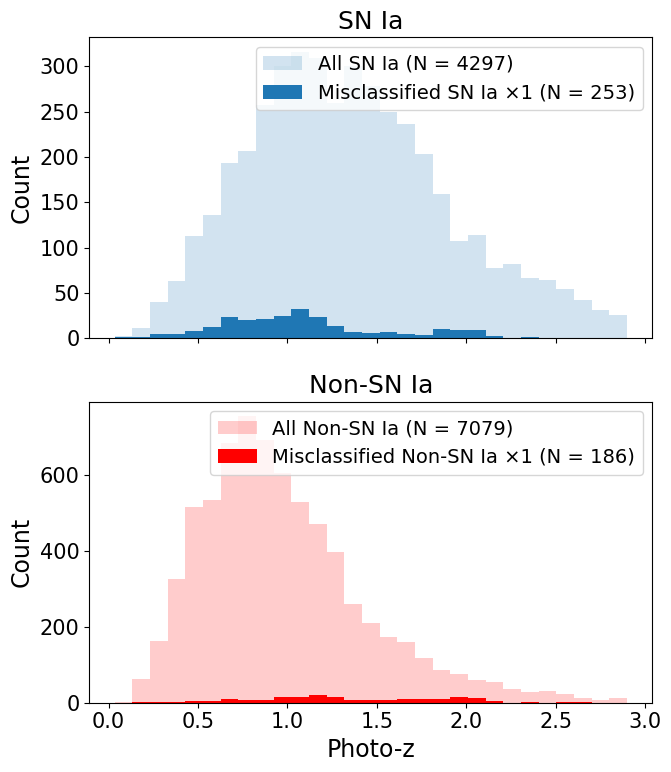

In [17]:
plt.rcParams.update({
    'font.size':        16,   # base size
    'axes.titlesize':   18,   # subplot titles
    'axes.labelsize':   17,   # x/y labels
    'xtick.labelsize':  15,
    'ytick.labelsize':  15,
    'legend.fontsize':  14,
})


y_pred_test = clf.predict(x_test).ravel()
y_true_test = np.asarray(y_test)
z_test      = x_test['Photo_z'].to_numpy()

mis    = y_pred_test != y_true_test
is_ia  = y_true_test == 'SNIa'
is_non = y_true_test == 'Non-SNIa'

SCALE = 1
bins = np.linspace(np.nanmin(z_test), np.nanmax(z_test), 30)

fig, axes = plt.subplots(2, 1, figsize=(7, 8), sharex=True)

# SN Ia: all vs misclassified (×SCALE)
m = is_ia & mis
axes[0].hist(z_test[is_ia], bins=bins, color='C0', alpha=0.2,
             label=f'All SN Ia (N = {is_ia.sum()})')
axes[0].hist(z_test[m], bins=bins, weights=np.full(m.sum(), SCALE),
             color='C0', lw=2,
             label=f'Misclassified SN Ia ×{SCALE} (N = {m.sum()})')
axes[0].set_title('SN Ia')
axes[0].set_ylabel('Count')
axes[0].legend()

# Non-SN Ia: all vs misclassified (×SCALE)
m = is_non & mis
axes[1].hist(z_test[is_non], bins=bins, color='red', alpha=0.2,
             label=f'All Non-SN Ia (N = {is_non.sum()})')
axes[1].hist(z_test[m], bins=bins, weights=np.full(m.sum(), SCALE),
             color='red',  lw=2,
             label=f'Misclassified Non-SN Ia ×{SCALE} (N = {m.sum()})')
axes[1].set_title('Non-SN Ia')
axes[1].set_ylabel('Count')
axes[1].set_xlabel('Photo-z')
axes[1].legend()

plt.tight_layout()

plt.savefig(f'{cfg.figures_dir}/Misclassified_z_hist.png')
plt.show()